<a href="https://colab.research.google.com/github/pablocastillo1296-sys/-Pr-ctica-8-Traslaci-n/blob/main/14%20Cinem%C3%A1tica%20Inversa/Cinem%C3%A1tica_inversa_IK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
!wget -nc 'https://raw.githubusercontent.com/Jegovila/SI2/refs/heads/main/14%20Cinem%C3%A1tica%20Inversa/Dibujar_Manipulador.py'

import numpy as np
import matplotlib.pyplot as plt
from Dibujar_Manipulador import dibujar_manipulador
from IPython import display

File ‘Dibujar_Manipulador.py’ already there; not retrieving.



Función de penalización

In [23]:
def Penalty(x, xl, xu):
    D = x.size
    z = 0

    # Aqui agrega tu función de penalización
    for j in range(D):
      if x[j] < xl[j]:
          z = z + (x[j]-xl[j]) ** 2
      elif x[j] > xu[j]:
          z = z + (x[j] - xu[j]) ** 2
      else:
          z = z + 0


    #----------------------------------

    return z

Función objetivo

In [24]:
f = lambda q: 0.5 * np.sum((np.array(pd) - p(q[0], q[1], q[2]))**2) # <----------------- Completar
fp = lambda x, xl, xu: f(x) + 1000 * Penalty(x, xl, xu); # <----------------- Completar

Parámetros

In [35]:
animacion = 1
pd = [0.6, 0.6]
a_1 = 0.35
a_2 = 0.35
a_3 = 0.25

beta = 1000
xl = np.array([-3.1416, -3.1416, -3.1416]) # <----------------- Completar
xu = np.array([3.1416, 3.1416, 3.1416]) # <----------------- Completar


G = 70 # <----------------- Completar
N = 50 # <----------------- Completar
D = 3

F = 0.6 # <----------------- Completar
CR = 0.9 # <----------------- Completar

# DE

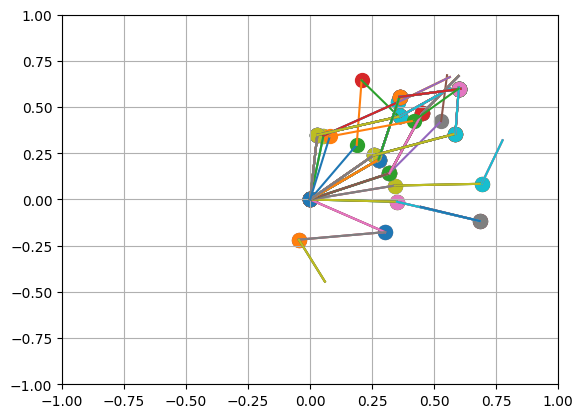

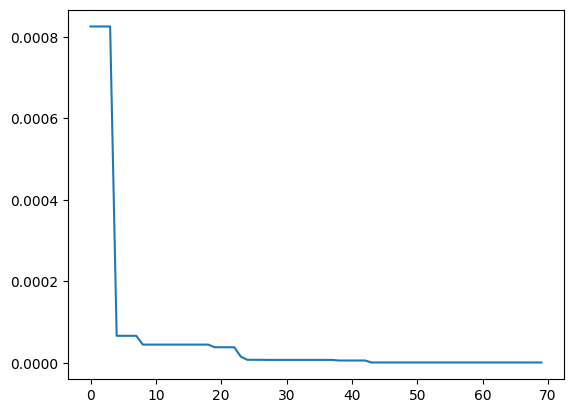

In [47]:
p = lambda theta_1, theta_2, theta_3: np.array([a_2*np.cos(theta_1 + theta_2) + a_1*np.cos(theta_1) + a_3*np.cos(theta_1 + theta_2 + theta_3),
                                                a_2*np.sin(theta_1 + theta_2) + a_1*np.sin(theta_1) + a_3*np.sin(theta_1 + theta_2 + theta_3)])

x = np.zeros((D, N))
fitness = np.zeros(N)

for i in range(N):
    x[:, i] = xl + (xu - xl) * np.random.rand(D)
    fitness[i] = fp(x[:, i], xl, xu)

fx_plot = np.zeros(G)

for n in range(G):
    if animacion:
        for i in range(0,N,50):
          display.display(plt.gcf())
          display.clear_output(wait=True)
          plt.scatter(pd[0], pd[1], marker='o', s=100)
          dibujar_manipulador(x[:, i])

    for i in range(N):

        # Mutación
        r1 = i
        while r1 == i:
            r1 = np.random.randint(N)

        r2 = r1
        while r2 == r1 or r2 == i:
            r2 = np.random.randint(N)

        r3 = r2
        while r3 == r2 or r3 == r1 or r3 == i:
            r3 = np.random.randint(N)

        v = x[:, r1] + F * (x[:, r2] - x[:, r3])

        # Recombinación
        u = np.zeros(D)

        for j in range(D):
            r = np.random.rand()

            if r <= CR:
                u[j] = v[j]
            else:
                u[j] = x[j, i]

        # Selección
        fitness_u = fp(u, xl, xu)

        if fitness_u < fitness[i]:
            x[:, i] = u.copy()
            fitness[i] = fitness_u

    fx_plot[n] = np.min(fitness)

igb = np.argmin(fitness)

q = x[:, igb]

theta_1 = q[0]
theta_2 = q[1]
theta_3 = q[2]

p = np.array([a_2*np.cos(theta_1 + theta_2) + a_1*np.cos(theta_1) + a_3*np.cos(theta_1 + theta_2 + theta_3),
                a_2*np.sin(theta_1 + theta_2) + a_1*np.sin(theta_1) + a_3*np.sin(theta_1 + theta_2 + theta_3)])

display.display(plt.gcf())
display.clear_output(wait=True)
dibujar_manipulador(q)

plt.show()
plt.plot(fx_plot)